In [32]:
# Define distributions for the background and signal

import numpy as np
from matplotlib import pyplot as plt
from scipy.integrate import quad 

XMIN = 0.
XMAX = 20.
intercept = 20.
slope = -1.

# Signal parameters
mean = 10.
sigma = 0.5
NBINS = 100
N_SAMPLES = 10000


class Linear:
    def __init__(self, slope, intercept, low=XMIN, high=XMAX):
        self.slope = slope
        self.intercept = intercept
        self.low = low
        self.high = high
        self.mass = []

    def evaluate(self, t):
        return self.intercept + self.slope * t

    def next(self):
        # Evaluate the endpoints because the linear function
        # is monotonic over this range.
        max_height = max(
            self.evaluate(self.low),
            self.evaluate(self.high)
        )

        while True:
            x = np.random.uniform(self.low, self.high)
            y = np.random.uniform(0.0, max_height)

            if y < self.evaluate(x):
                self.mass.append(x)
                return x


class Gaussian:
    def __init__(self, mean, stddev, low=XMIN, high=XMAX):
        self.mean = mean
        self.stddev = stddev
        self.low = low
        self.high = high
        self.mass = []

        # Normalisation over the allowed range
        self.norm = quad(self._pdf, low, high)[0]

    def _pdf(self, x):
        return (1 / (np.sqrt(2 * np.pi) * self.stddev)
                * np.exp(-0.5 * ((x - self.mean) / self.stddev)**2))

    def evaluate(self, x):
        return self._pdf(x) / self.norm

    def integral(self, low=None, high=None):
        if low is None:
            low = self.low
        if high is None:
            high = self.high

        return quad(self.evaluate, low, high)[0]

    def next(self):
        while True:
            x = np.random.normal(self.mean, self.stddev)

            if self.low <= x <= self.high:
                self.mass.append(x)
                return x

In [33]:
background = Linear(slope=slope, intercept=intercept, low=XMIN, high=XMAX)
signal = Gaussian(mean=mean, stddev=sigma, low=XMIN, high=XMAX)

sig_fraction = 0.029
combined_sample = []
signal_sample = []
background_sample = []

for _ in range(N_SAMPLES):
    if np.random.uniform() < sig_fraction:
        x = signal.next()
        signal_sample.append(x)
    else:
        x = background.next()
        background_sample.append(x)

    combined_sample.append(x)


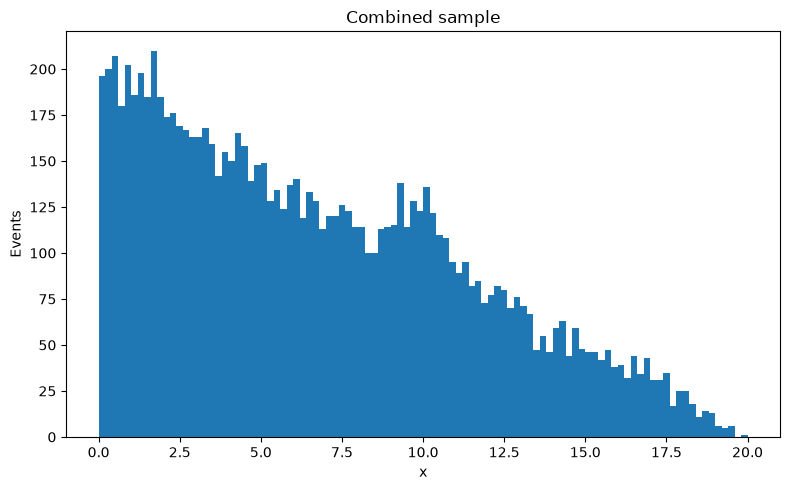

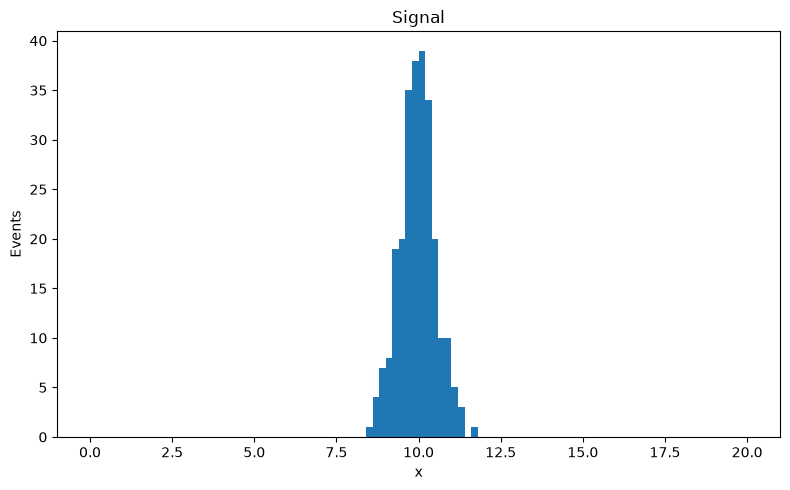

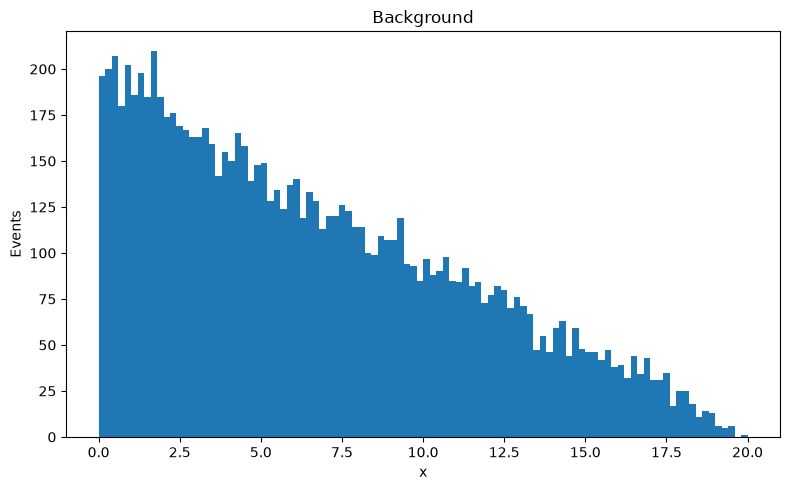

In [34]:
# Combined sample
plt.figure(figsize=(8, 5))
plt.hist(combined_sample, bins=NBINS, range=(XMIN, XMAX))
plt.xlabel('x')
plt.ylabel('Events')
plt.title('Combined sample')
plt.tight_layout()
plt.show()

# Signal sample
plt.figure(figsize=(8, 5))
plt.hist(signal_sample, bins=NBINS, range=(XMIN, XMAX))
plt.xlabel('x')
plt.ylabel('Events')
plt.title('Signal')
plt.tight_layout()
plt.show()

# Background sample
plt.figure(figsize=(8, 5))
plt.hist(background_sample, bins=NBINS, range=(XMIN, XMAX))
plt.xlabel('x')
plt.ylabel('Events')
plt.title('Background')
plt.tight_layout()
plt.show()

In [45]:

from scipy.special import erfinv

mu = 10000
sigma = np.sqrt(mu)
threshold = 10300

background_gaussian = Gaussian(mean=mu, stddev=sigma, low=mu - 5*sigma, high=mu + 5*sigma)

# Ratio of integrals
numerator = background_gaussian.integral(threshold, mu + 5*sigma)
denominator = background_gaussian.integral(mu - 5*sigma, mu + 5*sigma)

pvalue = numerator / denominator

# Convert p-value to number of standard deviations
n_sigmas = erfinv(1 - pvalue) * np.sqrt(2)

print(f"P-value: {pvalue:.6e}")
print(f"Significance: {n_sigmas:.3f} sigma")

P-value: 1.349612e-03
Significance: 3.205 sigma


In [46]:

from scipy.special import erfinv

mu = 5000
sigma = np.sqrt(mu)
threshold = 5300

background_gaussian = Gaussian(mean=mu, stddev=sigma, low=mu - 5*sigma, high=mu + 5*sigma)

# Ratio of integrals
numerator = background_gaussian.integral(threshold, mu + 5*sigma)
denominator = background_gaussian.integral(mu - 5*sigma, mu + 5*sigma)

pvalue = numerator / denominator

# Convert p-value to number of standard deviations
n_sigmas = erfinv(1 - pvalue) * np.sqrt(2)

print(f"P-value: {pvalue:.6e}")
print(f"Significance: {n_sigmas:.3f} sigma")

P-value: 1.075860e-05
Significance: 4.401 sigma


In [51]:
from iminuit import Minuit
from scipy.stats import chi2

data = np.asarray(combined_sample)
data = data[(data >= 5) & (data <= 15)]

# Fixed signal parameters
mean = 10.
sigma = 0.5

signal = Gaussian(mean, sigma, low=5, high=15)

# H0: Background only
def nll_H0(N_bkg, intercept, slope):
    background = Linear(slope, intercept, low=5, high=15)

    pdf = background.evaluate(data)
    pdf /= quad(background.evaluate, 5, 15)[0]

    if np.any(pdf <= 0) or N_bkg < 0:
        return np.inf

    return N_bkg - len(data)*np.log(N_bkg) - np.sum(np.log(pdf))


# H1: Gaussian signal + linear background
def nll_H1(N_sig, N_bkg, intercept, slope):
    background = Linear(slope, intercept, low=5, high=15)

    sig_pdf = signal.evaluate(data)
    sig_pdf /= signal.integral(5, 15)

    bkg_pdf = background.evaluate(data)
    bkg_pdf /= quad(background.evaluate, 5, 15)[0]

    pdf = N_sig*sig_pdf + N_bkg*bkg_pdf

    if np.any(pdf <= 0) or N_sig < 0 or N_bkg < 0:
        return np.inf

    return N_sig + N_bkg - np.sum(np.log(pdf))


# Fit H0
m0 = Minuit(nll_H0, N_bkg=len(data), intercept=20, slope=-1)
m0.errordef = Minuit.LIKELIHOOD
m0.limits["N_bkg"] = (0, None)
m0.migrad()
m0.hesse()

# Fit H1
m1 = Minuit(nll_H1, N_sig=150, N_bkg=len(data)-150,
            intercept=20, slope=-1)
m1.errordef = Minuit.LIKELIHOOD
m1.limits["N_sig", "N_bkg"] = (0, None)
m1.migrad()
m1.hesse()

# Likelihood ratio test
delta_chi2 = 2*(m0.fval - m1.fval)

# Wilks' theorem: 1 additional degree of freedom
pvalue = chi2.sf(delta_chi2, df=1)
significance = np.sqrt(delta_chi2)

print("H0 fit:", m0.values)
print("H1 fit:", m1.values)
print(f"Delta chi2: {delta_chi2:.3f}")
print(f"P-value: {pvalue:.6e}")
print(f"Significance: {significance:.3f} sigma")

H0 fit: <ValueView N_bkg=5006.000017617488 intercept=20.15019776359696 slope=-0.9922875639062927>
H1 fit: <ValueView N_sig=238.95605649414745 N_bkg=4767.087325525232 intercept=20.14787992469854 slope=-0.9927270630503834>
Delta chi2: 48.824
P-value: 2.799282e-12
Significance: 6.987 sigma


In [55]:
N_TOYS = 10000

# Observed test statistic from the original data
observed_delta_chi2 = 2 * (m0.fval - m1.fval)

# Create likelihood functions for a given dataset
def make_nlls(sample):

    def nll_H0(N_bkg, intercept, slope):
        background = Linear(slope, intercept, low=5, high=15)
        pdf = background.evaluate(sample)
        pdf /= quad(background.evaluate, 5, 15)[0]

        if N_bkg <= 0 or np.any(pdf <= 0):
            return np.inf

        return N_bkg - len(sample)*np.log(N_bkg) - np.sum(np.log(pdf))

    def nll_H1(N_sig, N_bkg, intercept, slope):
        background = Linear(slope, intercept, low=5, high=15)

        sig_pdf = signal.evaluate(sample)
        sig_pdf /= signal.integral(5, 15)

        bkg_pdf = background.evaluate(sample)
        bkg_pdf /= quad(background.evaluate, 5, 15)[0]

        pdf = N_sig*sig_pdf + N_bkg*bkg_pdf

        if N_sig < 0 or N_bkg <= 0 or np.any(pdf <= 0):
            return np.inf

        return N_sig + N_bkg - np.sum(np.log(pdf))

    return nll_H0, nll_H1


# Generate background-only toys and fit both hypotheses
toy_delta_chi2 = []

for i in range(N_TOYS):

    # Generate a Poisson-fluctuated number of background events
    n_events = np.random.poisson(m0.values["N_bkg"])

    background = Linear(
        m0.values["slope"],
        m0.values["intercept"],
        low=5, high=15
    )

    toy_data = np.array([background.next() for _ in range(n_events)])

    nll_H0_toy, nll_H1_toy = make_nlls(toy_data)

    # Fit H0
    fit0 = Minuit(
        nll_H0_toy,
        N_bkg=max(1, n_events),
        intercept=m0.values["intercept"],
        slope=m0.values["slope"]
    )
    fit0.errordef = Minuit.LIKELIHOOD
    fit0.limits["N_bkg"] = (0, None)
    fit0.migrad()

    # Fit H1
    fit1 = Minuit(
        nll_H1_toy,
        N_sig=150,
        N_bkg=max(1, n_events - 150),
        intercept=m0.values["intercept"],
        slope=m0.values["slope"]
    )
    fit1.errordef = Minuit.LIKELIHOOD
    fit1.limits["N_sig", "N_bkg"] = (0, None)
    fit1.migrad()

    if fit0.fmin.is_valid and fit1.fmin.is_valid:
        toy_delta_chi2.append(2 * (fit0.fval - fit1.fval))

toy_delta_chi2 = np.array(toy_delta_chi2)

print(f"Successful toys: {len(toy_delta_chi2)} / {N_TOYS}")

Successful toys: 10000 / 10000


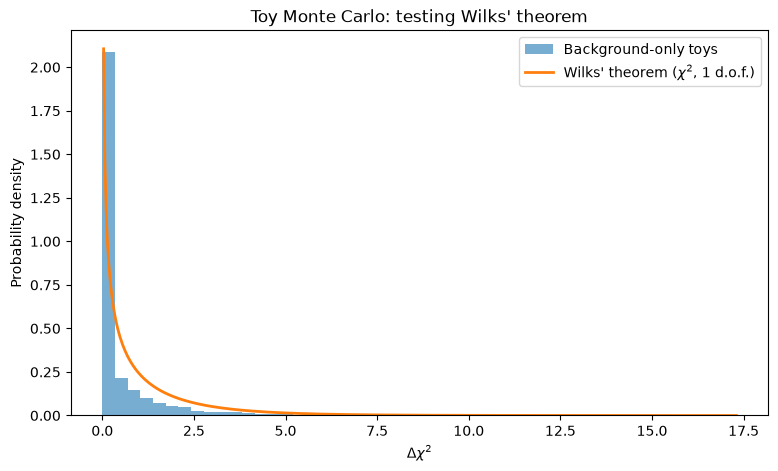

Observed delta chi2: 48.824
Toys exceeding observation: 0
Empirical p-value: 9.999000e-05
Wilks p-value: 2.799282e-12


In [56]:
# Theoretical chi-square distribution with 1 degree of freedom
x = np.linspace(0, max(10, np.max(toy_delta_chi2)), 500)

plt.figure(figsize=(9, 5))

plt.hist(toy_delta_chi2, bins=50, density=True,
         alpha=0.6, label="Background-only toys")

plt.plot(x, chi2.pdf(x, df=1), linewidth=2,
         label=r"Wilks' theorem ($\chi^2$, 1 d.o.f.)")


plt.xlabel(r"$\Delta\chi^2$")
plt.ylabel("Probability density")
plt.title("Toy Monte Carlo: testing Wilks' theorem")
plt.legend()
plt.show()

# Empirical and theoretical tail probabilities
n_exceed = np.sum(toy_delta_chi2 >= observed_delta_chi2)

empirical_p = (n_exceed + 1) / (len(toy_delta_chi2) + 1)
wilks_p = chi2.sf(observed_delta_chi2, df=1)

print(f"Observed delta chi2: {observed_delta_chi2:.3f}")
print(f"Toys exceeding observation: {n_exceed}")
print(f"Empirical p-value: {empirical_p:.6e}")
print(f"Wilks p-value: {wilks_p:.6e}")